# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

## Bài 6 — Giải thích thuật toán đếm xung đột

Mỗi phần tử `board[i]` là hàng của hậu ở cột `i`; có đúng một hậu mỗi cột, nên không cần đếm xung đột theo cột.

| Hàm | Cách tính | Thời gian | Bộ nhớ phụ |
|---|---|---|---|
| `conflicts_naive` | Quét n hàng; mỗi hàng so sánh với n hậu. Sau đó duyệt cặp cột để kiểm tra đường chéo. | $O(n^2)$ | $O(n)$ do bản sao và mảng tạm |
| `conflicts` | Đếm hậu trên từng hàng và hai hướng chéo, rồi cộng số cặp trong từng nhóm. | $O(n)$ | $O(n)$ |
| `conflicts_jit` | Cùng nguyên lý đếm nhóm; gộp các bộ đếm vào mảng 5n phần tử và biên dịch bằng Numba `@njit`. | $O(n)$ | $O(n)$ |

Với hậu tại cột $i$, hàng $r=\mathrm{board}[i]$:

- Bộ đếm hàng dùng khóa $r$.
- Hai hậu cùng một hướng chéo khi có cùng $i+r$; khóa nằm trong $[0,2n-2]$.
- Hướng chéo còn lại dùng $i-r+n$, nằm trong $[1,2n-1]$; cộng n để tránh chỉ số âm.
- Mỗi bộ đếm đường chéo dùng 2n ô cho thuận tiện; ô dư có giá trị 0 nên không ảnh hưởng tổng.

Một hàng hoặc đường chéo có k hậu tạo ra:

$$C(k,2)=\frac{k(k-1)}{2}.$$

Do đó:

$$f(\mathrm{board})=\sum_{\mathrm{hàng}} C(k,2)+\sum_{\mathrm{chéo\ 1}} C(k,2)+\sum_{\mathrm{chéo\ 2}} C(k,2).$$

Không đếm trùng: hai hậu ở các cột khác nhau không thể vừa cùng hàng vừa cùng đường chéo, cũng không thể cùng cả hai hướng chéo. Với $k=0$ hoặc $1$, số cặp bằng 0; phép chia nguyên `// 2` giữ kết quả là số nguyên.

Trong `conflicts_jit`, các vùng chỉ số là `r`, `n + (i+r)`, `3*n + (i-r+n)`. Ba vùng không chồng nhau và nằm trong 5n ô. Việc khởi tạo bộ đếm, duyệt n hậu, rồi cộng 5n giá trị đều tuyến tính theo n.

**Ví dụ:** Bàn cờ `[0,0,0,0]` có 4 hậu cùng hàng, nên $f=C(4,2)=6$. Bàn cờ `[0,1,2,3]` có 4 hậu cùng đường chéo, cũng có 6 xung đột. Bàn cờ `[1,3,0,2]` có 0 xung đột.

## Đo thời gian: tách biên dịch JIT và kiểm tra tính đúng

Các đầu vào đều là NumPy array **int64, một chiều, liên tục trong bộ nhớ**. Numba chuyên biệt hóa theo kiểu dữ liệu và bố trí mảng, không theo độ dài bàn cờ; dùng cùng kiểu giúp tránh biên dịch thêm trong phép đo.

Gọi `conflicts_jit` trước khi kiểm tra và đo lặp. Thời gian lời gọi đầu tiên bên dưới gồm cả biên dịch lẫn thực thi, không phải thời gian biên dịch thuần túy. Chi phí này được báo riêng và **không đưa vào bảng benchmark**.

In [5]:
from itertools import product
from time import perf_counter
import platform
import timeit
import pandas as pd
import numba
from IPython.display import display, Markdown

warm_board = np.ascontiguousarray([1, 3, 0, 2], dtype=np.int64)
started = perf_counter()
warm_result = conflicts_jit(warm_board)
jit_first_call_ms = (perf_counter() - started) * 1000
assert warm_result == 0
compiled_signatures = tuple(str(sig) for sig in conflicts_jit.signatures)
# Gọi lại sau khi đã biên dịch; đồng thời khởi động hai hàm Python.
assert conflicts_jit(warm_board) == conflicts(warm_board) == conflicts_naive(warm_board)

print(f'Python {platform.python_version()} | NumPy {np.__version__} | Numba {numba.__version__}')
print(f'Lời gọi JIT đầu tiên (biên dịch + thực thi): {jit_first_call_ms:.2f} ms')
print('Kiểu đã biên dịch:', compiled_signatures)

Python 3.10.11 | NumPy 2.2.6 | Numba 0.62.1
Lời gọi JIT đầu tiên (biên dịch + thực thi): 3946.09 ms
Kiểu đã biên dịch: ("(Array(int64, 1, 'C', False, aligned=True),)",)


### Kiểm tra ba hàm cho cùng kết quả

Đối chiếu với bộ kiểm tra độc lập duyệt từng cặp hậu: hai hậu xung đột nếu cùng hàng hoặc độ lệch hàng bằng độ lệch cột. Kiểm tra các ví dụ đã biết, toàn bộ bàn cờ với $n=1,2,3,4$ và bàn cờ ngẫu nhiên với $n=8,16,64$. Các kiểm tra này nằm ngoài vùng đo thời gian.

In [6]:
def conflicts_pair_reference(board):
    return sum(
        board[i] == board[j] or abs(int(board[i]) - int(board[j])) == j - i
        for i in range(len(board)) for j in range(i + 1, len(board))
    )

known_cases = [([1, 3, 0, 2], 0), ([0, 0, 0, 0], 6),
               ([0, 1, 2, 3], 6), ([3, 2, 1, 0], 6)]
for values, expected in known_cases:
    board = np.ascontiguousarray(values, dtype=np.int64)
    assert conflicts_naive(board) == conflicts(board) == conflicts_jit(board) == expected

correctness_count = 0
for n in range(1, 5):
    for values in product(range(n), repeat=n):
        board = np.ascontiguousarray(values, dtype=np.int64)
        expected = conflicts_pair_reference(board)
        assert conflicts_naive(board) == conflicts(board) == conflicts_jit(board) == expected
        correctness_count += 1

correctness_rng = np.random.default_rng(20261016)
for n in [8, 16, 64]:
    for _ in range(20):
        board = correctness_rng.integers(0, n, size=n, dtype=np.int64)
        expected = conflicts_pair_reference(board)
        assert conflicts_naive(board) == conflicts(board) == conflicts_jit(board) == expected
        correctness_count += 1
assert tuple(str(sig) for sig in conflicts_jit.signatures) == compiled_signatures
print(f'Đạt: {len(known_cases)} ví dụ và {correctness_count} bàn cờ kiểm tra độc lập.')

Đạt: 4 ví dụ và 348 bàn cờ kiểm tra độc lập.


## Benchmark trên nhiều kích thước

- Cỡ bàn cờ: **4, 8, 16, 32, 64, 128, 256, 512, 1024**.
- Mỗi cỡ tạo **20 bàn cờ** bằng RNG có seed cố định `1234`; ba hàm dùng đúng cùng các bàn cờ. Tạo dữ liệu và kiểm tra kết quả trước khi bắt đầu tính giờ.
- Đo theo lô 20 bàn cờ. Tự tăng số lô cho đến khi một phép đo kéo dài ít nhất **20 ms**, rồi đo **5 lần**; lấy **trung vị thời gian trên mỗi bàn cờ**. Các hàm nhanh được gọi nhiều lô hơn để tránh độ phân giải đồng hồ chi phối kết quả.
- Báo thêm **IQR = Q3 − Q1** của 5 phép đo. IQR phản ánh độ dao động trong lần benchmark này, không phải khoảng tin cậy thống kê.
- Luân phiên thứ tự ba hàm theo kích thước. Thời gian gồm lời gọi hàm, cấp phát bộ đếm và vòng lặp duyệt lô Python; không gồm biên dịch JIT, sinh bàn cờ, kiểm tra tính đúng hoặc hiển thị bảng/hình.
- Đơn vị thống nhất: **µs/bàn cờ**. Cột tăng tốc là tỷ số thời gian: lớn hơn 1 nghĩa là hàm sau nhanh hơn.

In [7]:
board_sizes = [4, 8, 16, 32, 64, 128, 256, 512, 1024]
boards_per_size = 20
timing_repeats = 5
minimum_batch_seconds = 0.02
timing_rng = np.random.default_rng(1234)
timing_functions = {
    'naive': conflicts_naive,
    'linear': conflicts,
    'jit': conflicts_jit,
}

def evaluate_batch(function, boards):
    total = 0
    for board in boards:
        total += int(function(board))
    return total

def measure_per_board(function, boards):
    timer = timeit.Timer(lambda: evaluate_batch(function, boards))
    batch_loops = 1
    while timer.timeit(number=batch_loops) < minimum_batch_seconds:
        batch_loops *= 2
    samples = np.asarray(timer.repeat(repeat=timing_repeats, number=batch_loops))
    samples_us = samples / (batch_loops * len(boards)) * 1e6
    return {
        'median_us': float(np.median(samples_us)),
        'iqr_us': float(np.percentile(samples_us, 75) - np.percentile(samples_us, 25)),
        'batch_loops': batch_loops,
        'samples_us': samples_us,
    }

timing_records = []
timing_samples = {}
for size_index, n in enumerate(board_sizes):
    boards = [timing_rng.integers(0, n, size=n, dtype=np.int64)
              for _ in range(boards_per_size)]
    expected = [conflicts_naive(board) for board in boards]
    assert expected == [conflicts(board) for board in boards]
    assert expected == [conflicts_jit(board) for board in boards]
    record = {'n': n}
    names = list(timing_functions)
    shift = size_index % len(names)
    for name in names[shift:] + names[:shift]:
        measured = measure_per_board(timing_functions[name], boards)
        record[f'{name}_us'] = measured['median_us']
        record[f'{name}_iqr_us'] = measured['iqr_us']
        timing_samples[n, name] = measured
    timing_records.append(record)

assert tuple(str(sig) for sig in conflicts_jit.signatures) == compiled_signatures
timing_results = pd.DataFrame(timing_records).set_index('n')
timing_results['naive_over_linear'] = timing_results.naive_us / timing_results.linear_us
timing_results['linear_over_jit'] = timing_results.linear_us / timing_results.jit_us
timing_results['naive_over_jit'] = timing_results.naive_us / timing_results.jit_us

timing_table = pd.DataFrame(index=timing_results.index)
for name, label in [('naive', 'Naive'), ('linear', 'Linear'), ('jit', 'JIT')]:
    timing_table[f'{label} µs/bàn cờ, trung vị (IQR)'] = [
        f'{median:.3f} ({iqr:.3f})'
        for median, iqr in zip(timing_results[f'{name}_us'], timing_results[f'{name}_iqr_us'])
    ]
timing_table['Naive / Linear (lần)'] = timing_results.naive_over_linear
timing_table['Linear / JIT (lần)'] = timing_results.linear_over_jit
timing_table['Naive / JIT (lần)'] = timing_results.naive_over_jit
display(timing_table.round(2))

,"Naive µs/bàn cờ, trung vị (IQR)","Linear µs/bàn cờ, trung vị (IQR)","JIT µs/bàn cờ, trung vị (IQR)",Naive / Linear (lần),Linear / JIT (lần),Naive / JIT (lần)
n,,,,,,
4,66.735 (14.980),17.286 (1.178),2.440 (0.805),3.86,7.09,27.36
8,160.709 (72.053),16.214 (2.640),1.431 (1.378),9.91,11.33,112.32
16,412.230 (134.985),56.581 (10.085),2.057 (0.040),7.29,27.51,200.40
32,1172.888 (454.105),80.132 (8.722),3.453 (0.440),14.64,23.21,339.66
64,3046.155 (525.895),261.471 (54.838),6.604 (1.384),11.65,39.60,461.29
128,7134.155 (801.185),277.424 (165.326),5.744 (0.657),25.72,48.30,1242.09
256,27489.380 (3133.060),742.490 (154.425),13.265 (1.761),37.02,55.97,2072.26
512,122667.700 (8330.695),1557.160 (350.075),16.599 (12.847),78.78,93.81,7390.11
1024,170699.450 (248375.570),1872.970 (58.970),53.738 (10.723),91.14,34.85,3176.52


## Đồ thị thời gian chạy và tốc độ tăng

Hình đầu dùng trục thời gian tuyến tính: toàn bộ ba hàm ở bên trái và phóng riêng hai hàm $O(n)$ ở bên phải. Hình sau dùng trục log–log và các đường tham chiếu $O(n^2)$, $O(n)$; hệ số của đường tham chiếu chỉ được chọn để dễ đối chiếu, không phải một thuật toán đo thêm.

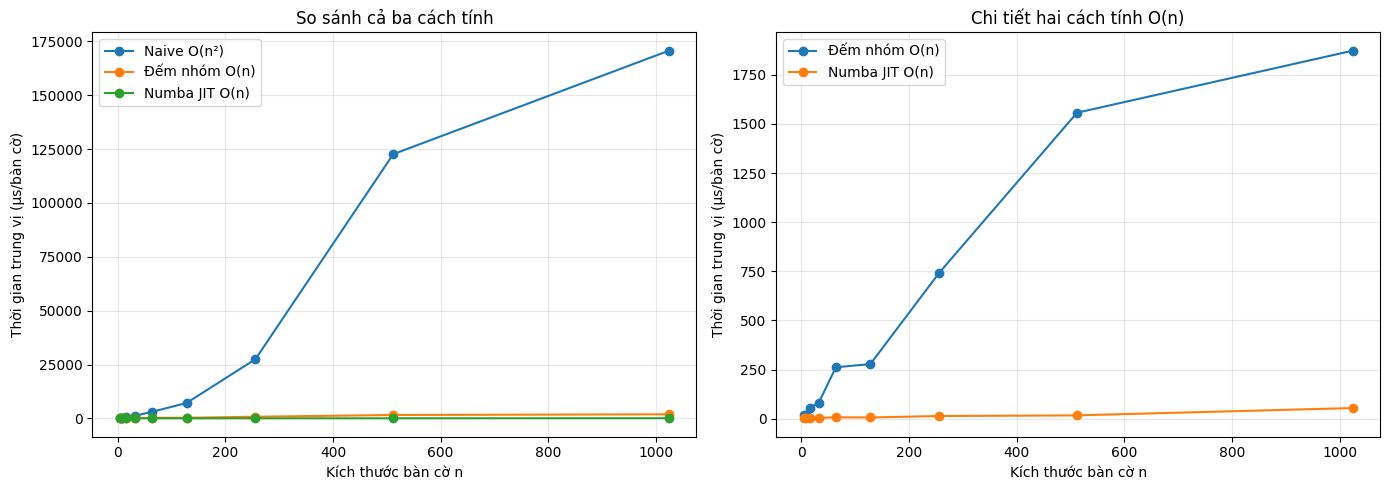

In [8]:
sizes = timing_results.index.to_numpy(dtype=float)
series = [('naive', 'Naive O(n²)'), ('linear', 'Đếm nhóm O(n)'), ('jit', 'Numba JIT O(n)')]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, label in series:
    axes[0].plot(sizes, timing_results[f'{name}_us'], 'o-', label=label)
for name, label in series[1:]:
    axes[1].plot(sizes, timing_results[f'{name}_us'], 'o-', label=label)
for ax in axes:
    ax.set_xlabel('Kích thước bàn cờ n')
    ax.set_ylabel('Thời gian trung vị (µs/bàn cờ)')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_title('So sánh cả ba cách tính')
axes[1].set_title('Chi tiết hai cách tính O(n)')
fig.tight_layout()
plt.show()

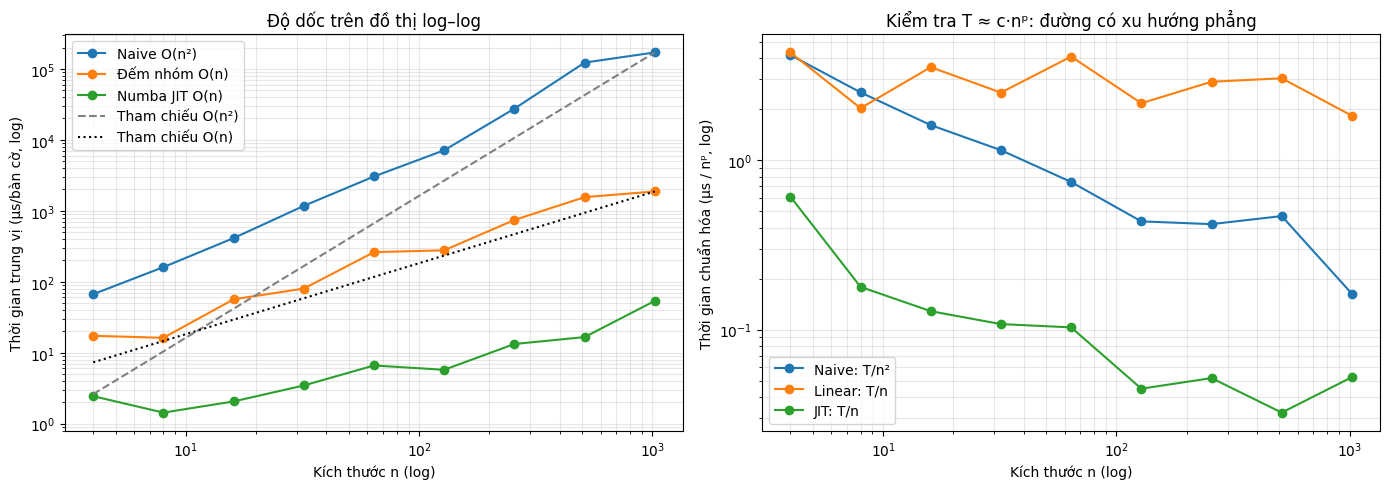

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, label in series:
    axes[0].loglog(sizes, timing_results[f'{name}_us'], 'o-', label=label)
anchor = sizes[-1]
axes[0].loglog(sizes, timing_results.naive_us.iloc[-1] * (sizes / anchor)**2,
              '--', color='gray', label='Tham chiếu O(n²)')
axes[0].loglog(sizes, timing_results.linear_us.iloc[-1] * (sizes / anchor),
              ':', color='black', label='Tham chiếu O(n)')
axes[0].set_xlabel('Kích thước n (log)')
axes[0].set_ylabel('Thời gian trung vị (µs/bàn cờ, log)')
axes[0].set_title('Độ dốc trên đồ thị log–log')

axes[1].loglog(sizes, timing_results.naive_us / sizes**2, 'o-', label='Naive: T/n²')
axes[1].loglog(sizes, timing_results.linear_us / sizes, 'o-', label='Linear: T/n')
axes[1].loglog(sizes, timing_results.jit_us / sizes, 'o-', label='JIT: T/n')
axes[1].set_xlabel('Kích thước n (log)')
axes[1].set_ylabel('Thời gian chuẩn hóa (µs / nᵖ, log)')
axes[1].set_title('Kiểm tra T ≈ c·nᵖ: đường có xu hướng phẳng')
for ax in axes:
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

## Nhận xét dựa trên số liệu thực đo

Ước lượng mô hình $T(n)\approx c n^p$ bằng hồi quy tuyến tính giữa $\log n$ và $\log T$ trên **bốn kích thước lớn nhất (128–1024)**. Đây là độ dốc thực nghiệm trong miền hữu hạn, không phải chứng minh độ phức tạp. Các cỡ nhỏ dễ bị chi phối bởi chi phí gọi hàm, cấp phát, đồng hồ và vòng lặp Python.

In [10]:
large_sizes = sizes[-4:]
empirical_slopes = {}
for name, _ in series:
    empirical_slopes[name] = float(np.polyfit(
        np.log(large_sizes), np.log(timing_results[f'{name}_us'].to_numpy()[-4:]), 1
    )[0])

largest = timing_results.iloc[-1]
largest_n = int(timing_results.index[-1])
observations = [
    f'- **Chi phí JIT ban đầu:** lời gọi đầu tiên mất {jit_first_call_ms:.2f} ms '
    '(gồm biên dịch và thực thi), được loại khỏi mọi phép đo lặp.',
    f'- **Tại n = {largest_n}:** Naive {largest.naive_us:.3f} µs/bàn cờ, '
    f'Linear {largest.linear_us:.3f} µs/bàn cờ, JIT {largest.jit_us:.3f} µs/bàn cờ.',
    f'- **Đổi thuật toán:** Linear nhanh hơn Naive {largest.naive_over_linear:.2f} lần ở n này.',
    f'- **Thực thi đã biên dịch:** JIT nhanh hơn Linear Python {largest.linear_over_jit:.2f} lần; '
    f'tổng cộng nhanh hơn Naive {largest.naive_over_jit:.2f} lần.',
    '- **Độ dốc log–log trên n = 128–1024:** '
    + ', '.join(f'{name}: p ≈ {empirical_slopes[name]:.2f}' for name, _ in series) + '.',
]
display(Markdown('\n'.join(observations)))

- **Chi phí JIT ban đầu:** lời gọi đầu tiên mất 3946.09 ms (gồm biên dịch và thực thi), được loại khỏi mọi phép đo lặp.
- **Tại n = 1024:** Naive 170699.450 µs/bàn cờ, Linear 1872.970 µs/bàn cờ, JIT 53.738 µs/bàn cờ.
- **Đổi thuật toán:** Linear nhanh hơn Naive 91.14 lần ở n này.
- **Thực thi đã biên dịch:** JIT nhanh hơn Linear Python 34.85 lần; tổng cộng nhanh hơn Naive 3176.52 lần.
- **Độ dốc log–log trên n = 128–1024:** naive: p ≈ 1.59, linear: p ≈ 0.93, jit: p ≈ 1.00.

## Phân biệt cải tiến thuật toán và biên dịch JIT

**Đổi cách đếm: $O(n^2)\rightarrow O(n)$.** Naive so sánh theo cặp và quét lặp nhiều lần. Đếm nhóm chỉ cần một lượt cập nhật bộ đếm và một lượt tính tổng trên số ô tỷ lệ với n. Về dài hạn, khi n tăng gấp đôi, phần công việc chính của Naive tăng khoảng 4 lần, còn hai bản đếm nhóm tăng khoảng 2 lần. Đây là lợi ích về độ phức tạp, có được ngay cả khi chưa dùng Numba.

**JIT: $O(n)\rightarrow O(n)$ với hệ số thực thi nhỏ hơn.** `@njit` biên dịch các vòng lặp và phép toán sang mã máy cho kiểu đầu vào cụ thể, giảm chi phí thông dịch Python. JIT không thay đổi số lượt đếm tuyến tính. Hai bản trong notebook còn khác cách bố trí bộ đếm và cách tính tổng, nên tỷ số Linear/JIT là lợi ích tổng thể của phiên bản đã biên dịch và điều chỉnh cách cài đặt; không phải phép tách riêng hoàn hảo chỉ một yếu tố biên dịch.

**Đọc số liệu đúng:** Hệ số tăng tốc thay đổi theo n, phần cứng, phiên bản thư viện và tải máy. Độ dốc đo được có thể lệch khỏi 2 hoặc 1 do miền kích thước hữu hạn, cấp phát, bộ nhớ đệm, overhead và nhiễu. Trong lần chạy được lưu, hai đường chuẩn hóa Linear/JIT còn dao động và độ dốc ước lượng thấp hơn 1; không được suy ra hai thuật toán có độ phức tạp dưới tuyến tính. Khi đường chuẩn hóa ổn định hơn, nó hỗ trợ nhận định về tốc độ tăng; phân tích vòng lặp ở trên mới là căn cứ xác định Big O. Không so sánh trực tiếp độ cao giữa T/n² và T/n vì chúng dùng số mũ chuẩn hóa khác nhau.

**Khi nào dùng JIT:** Hàm đếm xung đột được gọi rất nhiều trong Hill Climbing hoặc SA, nên chi phí biên dịch ban đầu có thể được bù bởi các lần gọi sau. Với ít lần gọi hoặc bàn cờ rất nhỏ, cần tính thêm chi phí ban đầu trước khi kết luận JIT có lợi. Đổi kiểu dữ liệu hoặc bố trí mảng có thể phát sinh một lần chuyên biệt hóa mới.

## Kết luận Bài 6

- Đã đối chiếu ba hàm và kiểm tra chúng trả về cùng số xung đột.
- Đã giải thích bộ đếm hàng/đường chéo, khóa chỉ số và công thức $C(k,2)$.
- Đã gọi JIT trước khi đo, benchmark chín kích thước với cùng dữ liệu, đo lặp và thống nhất đơn vị µs/bàn cờ.
- Đã vẽ thời gian, đồ thị log–log, đường tham chiếu/chuẩn hóa; báo cáo hệ số tăng tốc và độ dốc thực nghiệm.
- Kết luận: **đếm nhóm giảm độ phức tạp từ bậc hai xuống tuyến tính; Numba tăng tốc thực thi của thuật toán tuyến tính mà không đổi Big O.**